# 测试报告

<div class="report-subtitle">云端后端接口 · 等价类划分与边界值分析</div>

<div class="report-badges"><div class="report-badge"><b>17</b><span>核心被测方法</span></div><div class="report-badge"><b>126</b><span>设计用例</span></div><div class="report-badge"><b>3 类</b><span>正常 · 边界 · 异常</span></div><div class="report-badge"><b>6644</b><span>云端后端端口</span></div></div>

<div class="report-nav"><a href="#methods">方法测试</a>　·　<a href="#conclusion">总体结论</a>　·　<a href="#coverage">代码覆盖率</a>　·　<a href="#reproduce">复现说明</a></div>


|项目|说明|
|---|---|
|被测地址|`https://8.141.96.122:6644/api/v1`|
|测试层次|通过真实 HTTP 请求验证 Service 入口的集成测试|
|设计方法|等价类划分＋边界值分析|
|达标规则|每个方法至少 3 例，正常、合法边界、异常各至少 1 例|
|身份范围|6 个员工账号及独立管理员账号|
|证据形式|pytest 结果、原始请求/响应、业务读回、JaCoCo 报告|

每个方法按**功能与输入约束 → 用例设计 → 测试代码 → 实际数据 → 结论分析**展开。正常与合法边界输入预期成功，异常输入按契约拒绝；以实际返回和业务后置条件判定结果。

<div class="report-note">原始日志和请求响应默认折叠，点击即可查看完整记录；测试摘要、数据对照表与分析保持可见。密码和令牌已脱敏。</div>

范围为所列 17 个核心方法。数据写入限于本次创建的个人事项，并按登记 ID 清理。覆盖率与用例通过率分别报告。


In [1]:
import os,sys,json,uuid,getpass,pytest
from pathlib import Path
from datetime import datetime
from IPython.display import display,Markdown,HTML,Image
from html import escape
ROOT=Path.cwd().resolve()
if not (ROOT/'tools/matrix_runner.py').exists():
    candidates=[Path.cwd(),*Path.cwd().parents]
    ROOT=next(p/'notebooks/backend/方法三类用例专项' for p in candidates if (p/'notebooks/backend/方法三类用例专项/tools/matrix_runner.py').exists())
sys.path.insert(0,str(ROOT/'tools'))
from cloud_client import Cloud,BASE
from report_layout import CSS
display(HTML('<style>'+CSS+'</style>'))
from matrix_runner import execute_method,show_method
from result_analysis import display_overall_analysis
from output_display import fold_records
from cloud_coverage import CloudCoverage,show_coverage
SPECS=json.loads((ROOT/'方法用例设计.json').read_text())
assert BASE=='https://8.141.96.122:6644/api/v1'
RUN=ROOT/'runs'/('matrix6644-'+datetime.now().strftime('%Y%m%d-%H%M%S')+'-'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True)
AUTH=RUN/'auth';AUTH.mkdir()
SESSION=Cloud(AUTH)
CAPTURED={};REPORTS=[]
password=os.environ.get('PANDORA_CLOUD_PASSWORD')
if password is None:password=getpass.getpass('员工应用密码：')
admin_password=os.environ.get('PANDORA_CLOUD_ADMIN_PASSWORD')
if admin_password is None:admin_password=getpass.getpass('管理员应用密码（留空沿用员工密码）：') or password
PASSWORDS={'employee':password,'admin':admin_password}
# 需要真实覆盖率时临时给6644实例加载JaCoCo；留空仅做接口测试，覆盖率明确未采集。
ssh_password=os.environ.get('PANDORA_SSH_PASSWORD')
if ssh_password is None:ssh_password=getpass.getpass('覆盖率采集的服务器SSH密码（留空不采集）：')
COVERAGE=None
if ssh_password:
    COVERAGE=CloudCoverage(ROOT,RUN)
    try:COVERAGE.start(ssh_password)
    finally:ssh_password=None
status,health=SESSION.request('GET','/health')
assert status==200 and health['status']=='UP','云端不可用，停止，不切换到本地或443'
previous={key:os.environ.get(key) for key in ['PANDORA_CLOUD_PASSWORD','PANDORA_CLOUD_ADMIN_PASSWORD']}
os.environ.update(PANDORA_CLOUD_PASSWORD=password,PANDORA_CLOUD_ADMIN_PASSWORD=admin_password)
try:SESSION.login()
finally:
    for key,value in previous.items():
        if value is None:os.environ.pop(key,None)
        else:os.environ[key]=value
    password=admin_password=None
print('被测目标：',BASE,'；登录状态：',SESSION.login_results,'；结果目录：',RUN)
assert all(SESSION.login_results.get(key)==200 for key in ['A1','A2','A3','A4','A5','A6','ADMIN'])
fold_records([json.loads(line) for line in (AUTH/'requests.jsonl').read_text().splitlines()],'展开准备阶段原始数据（认证脱敏）')

6644覆盖采集已开始；监听仅回环地址，启动阶段数据已reset。部署包SHA256： f3182ca996f6b759b6c123a299dd2badee479e1eaa3d3fe071df32bf1e07889b


被测目标： https://8.141.96.122:6644/api/v1 ；登录状态： {'A1': 200, 'A2': 200, 'A3': 200, 'A4': 200, 'A5': 200, 'A6': 200, 'ADMIN': 200} ；结果目录： /Users/aoxiang/Desktop/软件测试/notebooks/backend/方法三类用例专项/runs/matrix6644-20261120-001908-614fac


<a id="methods"></a>
## 01　方法测试

下列章节逐方法核对正常、边界和异常输入。实际数据对照表中的记录行号可在对应方法的 `requests.jsonl` 中定位。

### 01.01　登录认证

|项目|说明|
|---|---|
|方法|`AuthService.login`|
|接口|`POST /auth/sessions`|
|功能|签发员工或独立管理员会话。|
|输入约束|identifier为字符串且原始长度≤80；员工手机号可去除显示分隔符；凭据必须匹配。|
|代码依据|`backend/src/main/java/cn/pandora/auth/AuthService.java:61`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_employee|正常|employee|有效员工手机号和密码|通常长度11的有效登录标识|200|
|N_admin|正常|admin|有效独立管理员账号和密码|管理员与员工登录分支分开|200|
|B_identifier80|边界|80|可规范化的合法员工标识|原始identifier长度上限80，69空格+11位手机号=80|200|
|E_identifier81|异常|81|超长登录标识|上限80的首次越界81，规范化前应拒绝|401|
|E_phone_type|异常|wrong_type|手机号为数组而非字符串|无效JSON类型等价类|400|
|E_password_wrong|异常|wrong_password|身份格式有效但密码错误|无效凭据等价类|401|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [2]:
CASES=[{'id': 'N_employee',
  'kind': '正常',
  'value': 'employee',
  'expected': 200,
  'equivalenceClass': '有效员工手机号和密码',
  'boundaryBasis': '通常长度11的有效登录标识'},
 {'id': 'N_admin',
  'kind': '正常',
  'value': 'admin',
  'expected': 200,
  'equivalenceClass': '有效独立管理员账号和密码',
  'boundaryBasis': '管理员与员工登录分支分开'},
 {'id': 'B_identifier80',
  'kind': '边界',
  'value': 80,
  'expected': 200,
  'equivalenceClass': '可规范化的合法员工标识',
  'boundaryBasis': '原始identifier长度上限80，69空格+11位手机号=80'},
 {'id': 'E_identifier81',
  'kind': '异常',
  'value': 81,
  'expected': 401,
  'equivalenceClass': '超长登录标识',
  'boundaryBasis': '上限80的首次越界81，规范化前应拒绝'},
 {'id': 'E_phone_type',
  'kind': '异常',
  'value': 'wrong_type',
  'expected': 400,
  'equivalenceClass': '手机号为数组而非字符串',
  'boundaryBasis': '无效JSON类型等价类'},
 {'id': 'E_password_wrong',
  'kind': '异常',
  'value': 'wrong_password',
  'expected': 401,
  'equivalenceClass': '身份格式有效但密码错误',
  'boundaryBasis': '无效凭据等价类'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_login_three_classes(cloud,case):
    # 使用隐藏输入的真实凭据，代码与结果文件不保存密码。
    admin=case['value']=='admin'
    payload={'accountType':'admin' if admin else 'employee','accountName' if admin else 'phone':os.environ.get('PANDORA_CLOUD_ADMIN_NAME','admin') if admin else '13800000001','password':os.environ['PANDORA_CLOUD_ADMIN_PASSWORD' if admin else 'PANDORA_CLOUD_PASSWORD']}
    if case['kind']=='边界' or case['value']==81:payload['phone']=' '*(case['value']-11)+'13800000001'
    if case['value']=='wrong_type':payload['phone']=[]
    if case['value']=='wrong_password':payload['password']='invalid-test-password'
    status,data=cloud.request('POST','/auth/sessions',payload)
    # 理想结果：普通和80字符边界可登录，81字符/类型错误/错误密码分别拒绝。
    assert status==case['expected']
    if status==200:
        alias='OWN-'+case['id'];cloud.tokens[alias]=data['token']
        try:
            session_status,session=cloud.request('GET','/auth/session',actor=alias)
            assert session_status==200
        finally:
            assert cloud.request('DELETE','/auth/sessions/current',actor=alias)[0]==200
            cloud.tokens.pop(alias,None)

# METHOD_SOURCE
CAPTURED['M01']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [3]:
SPEC=next(item for item in SPECS if item['id']=='M01')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M01'],SESSION,passwords=PASSWORDS))
PASSWORDS.clear()

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [4]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过6、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|2|2|2|
|边界|1|1|1|
|异常|3|3|3|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_employee|accountType=employee，phone原始长度=11|200|HTTP 200；会话accountType=employee，退出revoked=true|passed|1|
|正常/N_admin|accountType=admin，accountName原始长度=5|200|HTTP 200；会话accountType=admin，退出revoked=true|passed|4|
|边界/B_identifier80|accountType=employee，phone原始长度=80|200|HTTP 200；会话accountType=employee，退出revoked=true|passed|7|
|异常/E_identifier81|accountType=employee，phone原始长度=81|401|HTTP 401；code=BAD_CREDENTIALS|passed|10|
|异常/E_phone_type|accountType=employee，phone类型=list|400|HTTP 400；code=INVALID_LOGIN_CONTRACT|passed|11|
|异常/E_password_wrong|accountType=employee，phone原始长度=11|401|HTTP 401；code=BAD_CREDENTIALS|passed|12|


**测试结论与简析：**

正常输入：N_employee（accountType=employee，phone原始长度=11）实际HTTP 200；会话accountType=employee，退出revoked=true；N_admin（accountType=admin，accountName原始长度=5）实际HTTP 200；会话accountType=admin，退出revoked=true。

边界输入：B_identifier80（accountType=employee，phone原始长度=80）实际HTTP 200；会话accountType=employee，退出revoked=true。

异常输入：E_identifier81（accountType=employee，phone原始长度=81）实际HTTP 401；code=BAD_CREDENTIALS；E_phone_type（accountType=employee，phone类型=list）实际HTTP 400；code=INVALID_LOGIN_CONTRACT；E_password_wrong（accountType=employee，phone原始长度=11）实际HTTP 401；code=BAD_CREDENTIALS。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.02　个人事项列表

|项目|说明|
|---|---|
|方法|`DailyItemService.list`|
|接口|`GET /daily-items`|
|功能|按日期分页读取本人事项。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；日期必须可解析。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/DailyItemService.java:102`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [5]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={'date': '2026-11-20'}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/daily-items'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M02']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [6]:
SPEC=next(item for item in SPECS if item['id']=='M02')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M02'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [7]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|date=2026-11-20，limit=20，offset=0|200|HTTP 200；items=0，total=0，nextOffset=null|passed|1|
|边界/B_limit1|date=2026-11-20，limit=1，offset=0|200|HTTP 200；items=0，total=0，nextOffset=null|passed|2|
|边界/B_limit100|date=2026-11-20，limit=100，offset=0|200|HTTP 200；items=0，total=0，nextOffset=null|passed|3|
|异常/E_limit0|date=2026-11-20，limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|date=2026-11-20，limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|date=2026-11-20，limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|date=2026-11-20，limit=20，offset=2147483647|200|HTTP 200；items=0，total=0，nextOffset=null|passed|7|
|异常/E_offset_overflow|date=2026-11-20，limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（date=2026-11-20，limit=20，offset=0）实际HTTP 200；items=0，total=0，nextOffset=null。

边界输入：B_limit1（date=2026-11-20，limit=1，offset=0）实际HTTP 200；items=0，total=0，nextOffset=null；B_limit100（date=2026-11-20，limit=100，offset=0）实际HTTP 200；items=0，total=0，nextOffset=null；B_offset_max（date=2026-11-20，limit=20，offset=2147483647）实际HTTP 200；items=0，total=0，nextOffset=null。

异常输入：E_limit0（date=2026-11-20，limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（date=2026-11-20，limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（date=2026-11-20，limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（date=2026-11-20，limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 成功响应的items均为0，本轮没有验证非空列表的分页内容或筛选正确性。

### 01.03　个人事项日期汇总

|项目|说明|
|---|---|
|方法|`DailyItemService.summary`|
|接口|`GET /daily-items/summary`|
|功能|汇总个人事项日期范围内的计数。|
|输入约束|日期区间含首尾，长度必须为1–93天。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/DailyItemService.java:52`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_days30|正常|30|有效的含首尾日期范围|内部代表值30天|200|
|B_days1|边界|1|最短合法区间|精确下界1天，from=to|200|
|B_days93|边界|93|最长合法区间|精确上界93天|200|
|E_days0|异常|0|倒序区间|下界外相邻值0天|400|
|E_days94|异常|94|超长区间|上界外相邻值94天|400|
|E_invalid_date|异常|1900-02-29|非法公历日期|1900年不是闰年|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [8]:
CASES=[{'id': 'N_days30',
  'kind': '正常',
  'value': 30,
  'expected': 200,
  'equivalenceClass': '有效的含首尾日期范围',
  'boundaryBasis': '内部代表值30天'},
 {'id': 'B_days1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '最短合法区间',
  'boundaryBasis': '精确下界1天，from=to'},
 {'id': 'B_days93',
  'kind': '边界',
  'value': 93,
  'expected': 200,
  'equivalenceClass': '最长合法区间',
  'boundaryBasis': '精确上界93天'},
 {'id': 'E_days0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '倒序区间',
  'boundaryBasis': '下界外相邻值0天'},
 {'id': 'E_days94',
  'kind': '异常',
  'value': 94,
  'expected': 400,
  'equivalenceClass': '超长区间',
  'boundaryBasis': '上界外相邻值94天'},
 {'id': 'E_invalid_date',
  'kind': '异常',
  'value': '1900-02-29',
  'expected': 400,
  'equivalenceClass': '非法公历日期',
  'boundaryBasis': '1900年不是闰年'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_summary_three_classes(cloud,case):
    start=dt.date(2024,2,1)
    query={'from':str(start),'to':str(start+dt.timedelta(days=case['value']-1))} if isinstance(case['value'],int) else {'from':case['value'],'to':'1900-03-01'}
    status,data=cloud.request('GET','/daily-items/summary?'+urlencode(query),actor='A4')
    assert status==case['expected']
    if status==200:
        assert data['from']==query['from'] and data['to']==query['to']
        assert data['maxDays']==93
        assert all(query['from']<=row['date']<=query['to'] for row in data['days'])

# METHOD_SOURCE
CAPTURED['M03']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [9]:
SPEC=next(item for item in SPECS if item['id']=='M03')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M03'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [10]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过6、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|2|2|2|
|异常|3|3|3|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_days30|from=2024-02-01，to=2024-03-01|200|HTTP 200；from=2024-02-01，to=2024-03-01，maxDays=93，days记录数=0|passed|1|
|边界/B_days1|from=2024-02-01，to=2024-02-01|200|HTTP 200；from=2024-02-01，to=2024-02-01，maxDays=93，days记录数=0|passed|2|
|边界/B_days93|from=2024-02-01，to=2024-05-03|200|HTTP 200；from=2024-02-01，to=2024-05-03，maxDays=93，days记录数=0|passed|3|
|异常/E_days0|from=2024-02-01，to=2024-01-31|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_days94|from=2024-02-01，to=2024-05-04|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_invalid_date|from=1900-02-29，to=1900-03-01|400|HTTP 400；code=INVALID_INPUT|passed|6|


**测试结论与简析：**

正常输入：N_days30（from=2024-02-01，to=2024-03-01）实际HTTP 200；from=2024-02-01，to=2024-03-01，maxDays=93，days记录数=0。

边界输入：B_days1（from=2024-02-01，to=2024-02-01）实际HTTP 200；from=2024-02-01，to=2024-02-01，maxDays=93，days记录数=0；B_days93（from=2024-02-01，to=2024-05-03）实际HTTP 200；from=2024-02-01，to=2024-05-03，maxDays=93，days记录数=0。

异常输入：E_days0（from=2024-02-01，to=2024-01-31）实际HTTP 400；code=INVALID_INPUT；E_days94（from=2024-02-01，to=2024-05-04）实际HTTP 400；code=INVALID_INPUT；E_invalid_date（from=1900-02-29，to=1900-03-01）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 成功响应days记录数均为0，验证了日期范围及空汇总行为，尚未验证非零事项的逐日计数。

### 01.04　新增个人事项

|项目|说明|
|---|---|
|方法|`DailyItemService.create`|
|接口|`POST /daily-items`|
|功能|新建本人单日事项。|
|输入约束|正文为字符串，长度按Unicode码点计算，允许1–2000；单日日期有效。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/DailyItemService.java:151`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_text20|正常|20|非空且在长度内的正文|内部代表值20码点|200|
|B_text1|边界|1|最短合法正文|精确下界1码点|200|
|B_text2000|边界|2000|最长合法正文|精确上界2000码点|200|
|E_text0|异常|0|空正文|下界外相邻值0|400|
|E_text2001|异常|2001|超长正文|上界外相邻值2001|400|
|E_text_type|异常|number|正文为数字|无效JSON类型等价类|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [11]:
CASES=[{'id': 'N_text20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '非空且在长度内的正文',
  'boundaryBasis': '内部代表值20码点'},
 {'id': 'B_text1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '最短合法正文',
  'boundaryBasis': '精确下界1码点'},
 {'id': 'B_text2000',
  'kind': '边界',
  'value': 2000,
  'expected': 200,
  'equivalenceClass': '最长合法正文',
  'boundaryBasis': '精确上界2000码点'},
 {'id': 'E_text0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '空正文',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_text2001',
  'kind': '异常',
  'value': 2001,
  'expected': 400,
  'equivalenceClass': '超长正文',
  'boundaryBasis': '上界外相邻值2001'},
 {'id': 'E_text_type',
  'kind': '异常',
  'value': 'number',
  'expected': 400,
  'equivalenceClass': '正文为数字',
  'boundaryBasis': '无效JSON类型等价类'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_create_three_classes(cloud,case):
    text='汉'*case['value'] if isinstance(case['value'],int) else 123
    status,data=cloud.request('POST','/daily-items',{'date':DAY,'body':text},actor='A4',key=uuid.uuid4().hex)
    assert status==case['expected']
    if status==200:
        read_status,current=cloud.request('GET','/daily-items/'+data['id'],actor='A4')
        assert read_status==200 and current['body']==text and current['rowVersion']==1

# METHOD_SOURCE
CAPTURED['M04']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [12]:
SPEC=next(item for item in SPECS if item['id']=='M04')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M04'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [13]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过6、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|2|2|2|
|异常|3|3|3|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_text20|正文=20码点|200|HTTP 200；读回HTTP=200，读回正文长度=20，rowVersion=1，正文与输入一致=true|passed|1,2|
|边界/B_text1|正文=1码点|200|HTTP 200；读回HTTP=200，读回正文长度=1，rowVersion=1，正文与输入一致=true|passed|3,4|
|边界/B_text2000|正文=2000码点|200|HTTP 200；读回HTTP=200，读回正文长度=2000，rowVersion=1，正文与输入一致=true|passed|5,6|
|异常/E_text0|正文=0码点|400|HTTP 400；code=INVALID_INPUT|passed|7|
|异常/E_text2001|正文=2001码点|400|HTTP 400；code=INVALID_INPUT|passed|8|
|异常/E_text_type|正文类型=int|400|HTTP 400；code=INVALID_INPUT|passed|9|


**测试结论与简析：**

正常输入：N_text20（正文=20码点）实际HTTP 200；读回HTTP=200，读回正文长度=20，rowVersion=1，正文与输入一致=true。

边界输入：B_text1（正文=1码点）实际HTTP 200；读回HTTP=200，读回正文长度=1，rowVersion=1，正文与输入一致=true；B_text2000（正文=2000码点）实际HTTP 200；读回HTTP=200，读回正文长度=2000，rowVersion=1，正文与输入一致=true。

异常输入：E_text0（正文=0码点）实际HTTP 400；code=INVALID_INPUT；E_text2001（正文=2001码点）实际HTTP 400；code=INVALID_INPUT；E_text_type（正文类型=int）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.05　更新个人事项

|项目|说明|
|---|---|
|方法|`DailyItemService.change`|
|接口|`PATCH /daily-items/{id}`|
|功能|按行版本更新本人事项正文。|
|输入约束|正文1–2000码点；If-Match必须等于对象当前版本。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/DailyItemService.java:183`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_text20|正常|20|非空且在长度内的正文|内部代表值20码点|200|
|B_text1|边界|1|最短合法正文|精确下界1码点|200|
|B_text2000|边界|2000|最长合法正文|精确上界2000码点|200|
|E_text0|异常|0|空正文|下界外相邻值0|400|
|E_text2001|异常|2001|超长正文|上界外相邻值2001|400|
|E_text_type|异常|number|正文为数字|无效JSON类型等价类|400|
|E_version_missing|异常|20|版本前置条件缺失|If-Match未提供|428|
|E_version_stale|异常|20|版本前置条件陈旧|初始版本为1，输入0|412|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [14]:
CASES=[{'id': 'N_text20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '非空且在长度内的正文',
  'boundaryBasis': '内部代表值20码点'},
 {'id': 'B_text1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '最短合法正文',
  'boundaryBasis': '精确下界1码点'},
 {'id': 'B_text2000',
  'kind': '边界',
  'value': 2000,
  'expected': 200,
  'equivalenceClass': '最长合法正文',
  'boundaryBasis': '精确上界2000码点'},
 {'id': 'E_text0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '空正文',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_text2001',
  'kind': '异常',
  'value': 2001,
  'expected': 400,
  'equivalenceClass': '超长正文',
  'boundaryBasis': '上界外相邻值2001'},
 {'id': 'E_text_type',
  'kind': '异常',
  'value': 'number',
  'expected': 400,
  'equivalenceClass': '正文为数字',
  'boundaryBasis': '无效JSON类型等价类'},
 {'id': 'E_version_missing',
  'kind': '异常',
  'value': 20,
  'expected': 428,
  'equivalenceClass': '版本前置条件缺失',
  'boundaryBasis': 'If-Match未提供',
  'version': None},
 {'id': 'E_version_stale',
  'kind': '异常',
  'value': 20,
  'expected': 412,
  'equivalenceClass': '版本前置条件陈旧',
  'boundaryBasis': '初始版本为1，输入0',
  'version': 0}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_change_three_classes(cloud,case):
    # 每个用例新建独立对象，不让前一用例的版本变化影响后一用例。
    original='before-'+uuid.uuid4().hex
    row=create_owned(cloud,original)
    text='汉'*case['value'] if isinstance(case['value'],int) else 123
    status,data=cloud.request('PATCH','/daily-items/'+row['id'],{'body':text},actor='A4',key=uuid.uuid4().hex,version=case.get('version',1))
    assert status==case['expected']
    read_status,current=cloud.request('GET','/daily-items/'+row['id'],actor='A4')
    assert read_status==200
    if status==200:assert current['body']==text and current['rowVersion']==2
    else:assert current['body']==original and current['rowVersion']==1

# METHOD_SOURCE
CAPTURED['M05']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [15]:
SPEC=next(item for item in SPECS if item['id']=='M05')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M05'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [16]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|2|2|2|
|异常|5|5|5|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_text20|正文=20码点，If-Match="1"|200|HTTP 200；读回HTTP=200，读回正文长度=20，rowVersion=2，正文与输入一致=true|passed|2,3|
|边界/B_text1|正文=1码点，If-Match="1"|200|HTTP 200；读回HTTP=200，读回正文长度=1，rowVersion=2，正文与输入一致=true|passed|5,6|
|边界/B_text2000|正文=2000码点，If-Match="1"|200|HTTP 200；读回HTTP=200，读回正文长度=2000，rowVersion=2，正文与输入一致=true|passed|8,9|
|异常/E_text0|正文=0码点，If-Match="1"|400|HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true|passed|11,12|
|异常/E_text2001|正文=2001码点，If-Match="1"|400|HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true|passed|14,15|
|异常/E_text_type|正文类型=int，If-Match="1"|400|HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true|passed|17,18|
|异常/E_version_missing|正文=20码点，If-Match=null|428|HTTP 428；code=PRECONDITION_REQUIRED，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true|passed|20,21|
|异常/E_version_stale|正文=20码点，If-Match="0"|412|HTTP 412；code=VERSION_CONFLICT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true|passed|23,24|


**测试结论与简析：**

正常输入：N_text20（正文=20码点，If-Match="1"）实际HTTP 200；读回HTTP=200，读回正文长度=20，rowVersion=2，正文与输入一致=true。

边界输入：B_text1（正文=1码点，If-Match="1"）实际HTTP 200；读回HTTP=200，读回正文长度=1，rowVersion=2，正文与输入一致=true；B_text2000（正文=2000码点，If-Match="1"）实际HTTP 200；读回HTTP=200，读回正文长度=2000，rowVersion=2，正文与输入一致=true。

异常输入：E_text0（正文=0码点，If-Match="1"）实际HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true；E_text2001（正文=2001码点，If-Match="1"）实际HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true；E_text_type（正文类型=int，If-Match="1"）实际HTTP 400；code=INVALID_INPUT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true；E_version_missing（正文=20码点，If-Match=null）实际HTTP 428；code=PRECONDITION_REQUIRED，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true；E_version_stale（正文=20码点，If-Match="0"）实际HTTP 412；code=VERSION_CONFLICT，读回HTTP=200，读回正文长度=39，rowVersion=1，拒绝后原文未变=true。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.06　删除个人事项

|项目|说明|
|---|---|
|方法|`DailyItemService.delete`|
|接口|`DELETE /daily-items/{id}`|
|功能|按当前版本删除本人事项。|
|输入约束|新对象行版本从1开始；删除时须提供匹配的版本。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/DailyItemService.java:229`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_version2|正常|2|存在且版本匹配的本人对象|先将本次新建对象更新至版本2|200|
|B_version1|边界|1|最小有效对象版本|对象刚创建时初始版本1|200|
|E_version0|异常|0|陈旧版本|小于初始版本的相邻值0|412|
|E_version_missing|异常|None|缺少版本前置条件|If-Match缺失|428|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [17]:
CASES=[{'id': 'N_version2',
  'kind': '正常',
  'value': 2,
  'expected': 200,
  'equivalenceClass': '存在且版本匹配的本人对象',
  'boundaryBasis': '先将本次新建对象更新至版本2'},
 {'id': 'B_version1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '最小有效对象版本',
  'boundaryBasis': '对象刚创建时初始版本1'},
 {'id': 'E_version0',
  'kind': '异常',
  'value': 0,
  'expected': 412,
  'equivalenceClass': '陈旧版本',
  'boundaryBasis': '小于初始版本的相邻值0'},
 {'id': 'E_version_missing',
  'kind': '异常',
  'value': None,
  'expected': 428,
  'equivalenceClass': '缺少版本前置条件',
  'boundaryBasis': 'If-Match缺失'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_delete_three_classes(cloud,case):
    row=create_owned(cloud,'delete-'+uuid.uuid4().hex)
    if case['value']==2:
        assert cloud.request('PATCH','/daily-items/'+row['id'],{'body':'updated'},actor='A4',key=uuid.uuid4().hex,version=1)[0]==200
    status,data=cloud.request('DELETE','/daily-items/'+row['id'],actor='A4',key=uuid.uuid4().hex,version=case['value'])
    assert status==case['expected']
    check_status,current=cloud.request('GET','/daily-items/'+row['id'],actor='A4')
    assert check_status==(404 if status==200 else 200)

# METHOD_SOURCE
CAPTURED['M06']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [18]:
SPEC=next(item for item in SPECS if item['id']=='M06')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M06'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [19]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过4、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|1|1|1|
|异常|2|2|2|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_version2|If-Match="2"|200|HTTP 200；读回HTTP=404，deleted=true|passed|3,4|
|边界/B_version1|If-Match="1"|200|HTTP 200；读回HTTP=404，deleted=true|passed|6,7|
|异常/E_version0|If-Match="0"|412|HTTP 412；code=VERSION_CONFLICT，读回HTTP=200，读回正文长度=39，rowVersion=1|passed|9,10|
|异常/E_version_missing|If-Match=null|428|HTTP 428；code=PRECONDITION_REQUIRED，读回HTTP=200，读回正文长度=39，rowVersion=1|passed|12,13|


**测试结论与简析：**

正常输入：N_version2（If-Match="2"）实际HTTP 200；读回HTTP=404，deleted=true。

边界输入：B_version1（If-Match="1"）实际HTTP 200；读回HTTP=404，deleted=true。

异常输入：E_version0（If-Match="0"）实际HTTP 412；code=VERSION_CONFLICT，读回HTTP=200，读回正文长度=39，rowVersion=1；E_version_missing（If-Match=null）实际HTTP 428；code=PRECONDITION_REQUIRED，读回HTTP=200，读回正文长度=39，rowVersion=1。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.07　员工目录查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.users`|
|接口|`GET /users`|
|功能|读取员工可见目录。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:75`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|
|N_admin20|正常|20|管理员目录有效分页|管理员调用同一users方法的admin分支|200|
|B_admin100|边界|100|管理员目录合法最大分页|精确上界100|200|
|E_admin101|异常|101|管理员目录越界|上界外相邻值101|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [20]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648},
 {'id': 'N_admin20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '管理员目录有效分页',
  'boundaryBasis': '管理员调用同一users方法的admin分支',
  'actor': 'ADMIN',
  'path': '/admin/users'},
 {'id': 'B_admin100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '管理员目录合法最大分页',
  'boundaryBasis': '精确上界100',
  'actor': 'ADMIN',
  'path': '/admin/users'},
 {'id': 'E_admin101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '管理员目录越界',
  'boundaryBasis': '上界外相邻值101',
  'actor': 'ADMIN',
  'path': '/admin/users'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET',case.get('path','/users')+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M07']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [21]:
SPEC=next(item for item in SPECS if item['id']=='M07')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M07'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [22]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过11、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|2|2|2|
|边界|4|4|4|
|异常|5|5|5|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=1，total=1，nextOffset=null|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=1，nextOffset=null|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=1，total=1，nextOffset=null|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=1，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|
|正常/N_admin20|limit=20，offset=0|200|HTTP 200；items=14，total=14，nextOffset=null|passed|9|
|边界/B_admin100|limit=100，offset=0|200|HTTP 200；items=14，total=14，nextOffset=null|passed|10|
|异常/E_admin101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|11|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=1，total=1，nextOffset=null；N_admin20（limit=20，offset=0）实际HTTP 200；items=14，total=14，nextOffset=null。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=1，nextOffset=null；B_limit100（limit=100，offset=0）实际HTTP 200；items=1，total=1，nextOffset=null；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=1，nextOffset=null；B_admin100（limit=100，offset=0）实际HTTP 200；items=14，total=14，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT；E_admin101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回1、14条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.08　工作日志查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.logs`|
|接口|`GET /work-logs`|
|功能|读取本人工作日志。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:200`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [23]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={'scope': 'self'}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/work-logs'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M08']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [24]:
SPEC=next(item for item in SPECS if item['id']=='M08')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M08'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [25]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|scope=self，limit=20，offset=0|200|HTTP 200；items=3，total=3，nextOffset=null|passed|1|
|边界/B_limit1|scope=self，limit=1，offset=0|200|HTTP 200；items=1，total=3，nextOffset=1|passed|2|
|边界/B_limit100|scope=self，limit=100，offset=0|200|HTTP 200；items=3，total=3，nextOffset=null|passed|3|
|异常/E_limit0|scope=self，limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|scope=self，limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|scope=self，limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|scope=self，limit=20，offset=2147483647|200|HTTP 200；items=0，total=3，nextOffset=null|passed|7|
|异常/E_offset_overflow|scope=self，limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（scope=self，limit=20，offset=0）实际HTTP 200；items=3，total=3，nextOffset=null。

边界输入：B_limit1（scope=self，limit=1，offset=0）实际HTTP 200；items=1，total=3，nextOffset=1；B_limit100（scope=self，limit=100，offset=0）实际HTTP 200；items=3，total=3，nextOffset=null；B_offset_max（scope=self，limit=20，offset=2147483647）实际HTTP 200；items=0，total=3，nextOffset=null。

异常输入：E_limit0（scope=self，limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（scope=self，limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（scope=self，limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（scope=self，limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回3条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.09　个人通知查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.notifications`|
|接口|`GET /notifications`|
|功能|读取本人通知。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:446`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [26]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/notifications'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M09']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [27]:
SPEC=next(item for item in SPECS if item['id']=='M09')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M09'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [28]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=20，total=105，nextOffset=20|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=105，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=100，total=105，nextOffset=100|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=105，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=20，total=105，nextOffset=20。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=105，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=100，total=105，nextOffset=100；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=105，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.10　管理员小组查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.adminTeams`|
|接口|`GET /admin/teams`|
|功能|管理员读取小组目录。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:1174`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [29]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','ADMIN')
    status,data=cloud.request('GET','/admin/teams'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M10']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [30]:
SPEC=next(item for item in SPECS if item['id']=='M10')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M10'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [31]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=4，total=4，nextOffset=null|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=4，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=4，total=4，nextOffset=null|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=4，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=4，total=4，nextOffset=null。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=4，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=4，total=4，nextOffset=null；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=4，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回4条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.11　管理员审计查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.audit`|
|接口|`GET /admin/audit-logs`|
|功能|管理员读取审计记录。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:1179`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [32]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','ADMIN')
    status,data=cloud.request('GET','/admin/audit-logs'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M11']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [33]:
SPEC=next(item for item in SPECS if item['id']=='M11')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M11'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [34]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=20，total=601，nextOffset=20|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=601，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=100，total=601，nextOffset=100|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=601，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=20，total=601，nextOffset=20。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=601，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=100，total=601，nextOffset=100；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=601，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.12　管理员通知查询

|项目|说明|
|---|---|
|方法|`WorkspaceService.adminNotifications`|
|接口|`GET /admin/notifications`|
|功能|管理员读取投递通知。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/workspace/WorkspaceService.java:567`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [35]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','ADMIN')
    status,data=cloud.request('GET','/admin/notifications'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M12']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [36]:
SPEC=next(item for item in SPECS if item['id']=='M12')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M12'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [37]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=20，total=497，nextOffset=20|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=497，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=100，total=497，nextOffset=100|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=497，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=20，total=497，nextOffset=20。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=497，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=100，total=497，nextOffset=100；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=497，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.13　任务列表查询

|项目|说明|
|---|---|
|方法|`TaskService.list`|
|接口|`GET /tasks`|
|功能|读取本人任务列表。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/task/TaskService.java:91`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [38]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={'scope': 'self'}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/tasks'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M13']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [39]:
SPEC=next(item for item in SPECS if item['id']=='M13')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M13'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [40]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|scope=self，limit=20，offset=0|200|HTTP 200；items=20，total=21|passed|1|
|边界/B_limit1|scope=self，limit=1，offset=0|200|HTTP 200；items=1，total=21|passed|2|
|边界/B_limit100|scope=self，limit=100，offset=0|200|HTTP 200；items=21，total=21|passed|3|
|异常/E_limit0|scope=self，limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|scope=self，limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|scope=self，limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|scope=self，limit=20，offset=2147483647|200|HTTP 200；items=0，total=21|passed|7|
|异常/E_offset_overflow|scope=self，limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（scope=self，limit=20，offset=0）实际HTTP 200；items=20，total=21。

边界输入：B_limit1（scope=self，limit=1，offset=0）实际HTTP 200；items=1，total=21；B_limit100（scope=self，limit=100，offset=0）实际HTTP 200；items=21，total=21；B_offset_max（scope=self，limit=20，offset=2147483647）实际HTTP 200；items=0，total=21。

异常输入：E_limit0（scope=self，limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（scope=self，limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（scope=self，limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（scope=self，limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回21条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.14　个人任务表查询

|项目|说明|
|---|---|
|方法|`TaskService.table`|
|接口|`GET /tasks/table`|
|功能|读取个人任务表单投影。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/task/TaskService.java:117`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [41]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/tasks/table'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M14']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [42]:
SPEC=next(item for item in SPECS if item['id']=='M14')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M14'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [43]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=20，total=21，nextOffset=20|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=21，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=21，total=21，nextOffset=null|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=21，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=20，total=21，nextOffset=20。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=21，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=21，total=21，nextOffset=null；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=21，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回21条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.15　管理员任务定位

|项目|说明|
|---|---|
|方法|`TaskService.adminTasks`|
|接口|`GET /admin/tasks`|
|功能|管理员定位任务。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；非整数或越界拒绝。|
|代码依据|`backend/src/main/java/cn/pandora/task/TaskService.java:330`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [44]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','ADMIN')
    status,data=cloud.request('GET','/admin/tasks'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M15']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [45]:
SPEC=next(item for item in SPECS if item['id']=='M15')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M15'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [46]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|limit=20，offset=0|200|HTTP 200；items=20，total=62，nextOffset=20|passed|1|
|边界/B_limit1|limit=1，offset=0|200|HTTP 200；items=1，total=62，nextOffset=1|passed|2|
|边界/B_limit100|limit=100，offset=0|200|HTTP 200；items=62，total=62，nextOffset=null|passed|3|
|异常/E_limit0|limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|limit=20，offset=2147483647|200|HTTP 200；items=0，total=62，nextOffset=null|passed|7|
|异常/E_offset_overflow|limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（limit=20，offset=0）实际HTTP 200；items=20，total=62，nextOffset=20。

边界输入：B_limit1（limit=1，offset=0）实际HTTP 200；items=1，total=62，nextOffset=1；B_limit100（limit=100，offset=0）实际HTTP 200；items=62，total=62，nextOffset=null；B_offset_max（limit=20，offset=2147483647）实际HTTP 200；items=0，total=62，nextOffset=null。

异常输入：E_limit0（limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回62条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

### 01.16　负责人候选查询

|项目|说明|
|---|---|
|方法|`TaskService.assigneeCandidates`|
|接口|`GET /assignee-candidates`|
|功能|读取有权限分派的负责人候选。|
|输入约束|q长度0–100；purpose只能为create或edit。|
|代码依据|`backend/src/main/java/cn/pandora/task/TaskService.java:435`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_query|正常|10|合法检索字符串|长度10的普通检索|200|
|B_query0|边界|0|空检索返回允许候选范围|精确下界0字符|200|
|B_query100|边界|100|最长合法检索|精确上界100字符|200|
|E_query101|异常|101|检索过长|上界外相邻值101|400|
|E_purpose|异常|10|无效操作场景枚举|purpose不属于create/edit|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [47]:
CASES=[{'id': 'N_query',
  'kind': '正常',
  'value': 10,
  'expected': 200,
  'equivalenceClass': '合法检索字符串',
  'boundaryBasis': '长度10的普通检索'},
 {'id': 'B_query0',
  'kind': '边界',
  'value': 0,
  'expected': 200,
  'equivalenceClass': '空检索返回允许候选范围',
  'boundaryBasis': '精确下界0字符'},
 {'id': 'B_query100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '最长合法检索',
  'boundaryBasis': '精确上界100字符'},
 {'id': 'E_query101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '检索过长',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_purpose',
  'kind': '异常',
  'value': 10,
  'expected': 400,
  'equivalenceClass': '无效操作场景枚举',
  'boundaryBasis': 'purpose不属于create/edit',
  'purpose': 'invalid'}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_candidates_three_classes(cloud,case):
    query={'q':'汉'*case['value'],'purpose':case.get('purpose','create')}
    status,data=cloud.request('GET','/assignee-candidates?'+urlencode(query),actor='A4')
    assert status==case['expected']
    if status==200:assert isinstance(data['items'],list)

# METHOD_SOURCE
CAPTURED['M16']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [48]:
SPEC=next(item for item in SPECS if item['id']=='M16')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M16'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [49]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过5、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|2|2|2|
|异常|2|2|2|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_query|q长度=10，purpose=create|200|HTTP 200；items=0，purpose=create|passed|1|
|边界/B_query0|q长度=0，purpose=create|200|HTTP 200；items=14，purpose=create|passed|2|
|边界/B_query100|q长度=100，purpose=create|200|HTTP 200；items=0，purpose=create|passed|3|
|异常/E_query101|q长度=101，purpose=create|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_purpose|q长度=10，purpose=invalid|400|HTTP 400；code=INVALID_INPUT|passed|5|


**测试结论与简析：**

正常输入：N_query（q长度=10，purpose=create）实际HTTP 200；items=0，purpose=create。

边界输入：B_query0（q长度=0，purpose=create）实际HTTP 200；items=14，purpose=create；B_query100（q长度=100，purpose=create）实际HTTP 200；items=0，purpose=create。

异常输入：E_query101（q长度=101，purpose=create）实际HTTP 400；code=INVALID_INPUT；E_purpose（q长度=10，purpose=invalid）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。

### 01.17　申请列表查询

|项目|说明|
|---|---|
|方法|`TaskService.approvals`|
|接口|`GET /approval-requests`|
|功能|读取本人相关的申请列表。|
|输入约束|limit∈[1,100]；offset∈[0,2147483647]；mine可为all/reviewer/applicant。|
|代码依据|`backend/src/main/java/cn/pandora/task/TaskService.java:675`|

#### A　用例设计

|编号|类别|输入/代表值|等价类|边界依据|理想HTTP|
|---|---|---|---|---|---|
|N_limit20|正常|20|允许范围内的分页长度|内部代表值20|200|
|B_limit1|边界|1|合法最小分页长度|精确下界1|200|
|B_limit100|边界|100|合法最大分页长度|精确上界100|200|
|E_limit0|异常|0|小于允许范围|下界外相邻值0|400|
|E_limit101|异常|101|大于允许范围|上界外相邻值101|400|
|E_limit_text|异常|x|分页值非整数|无效类型/格式等价类|400|
|B_offset_max|边界|20|最大合法分页偏移|offset的Integer.MAX_VALUE=2147483647|200|
|E_offset_overflow|异常|20|偏移数值溢出|offset首次越界2147483648|400|

每条参数是独立pytest用例；正常与合法边界预期成功，异常预期明确拒绝。

#### B　测试代码与过程

修改下方 `CASES` 与断言后，从新内核完整运行。逐例核对 HTTP 状态和读回数据，并保留独立结果目录。

In [50]:
CASES=[{'id': 'N_limit20',
  'kind': '正常',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '允许范围内的分页长度',
  'boundaryBasis': '内部代表值20'},
 {'id': 'B_limit1',
  'kind': '边界',
  'value': 1,
  'expected': 200,
  'equivalenceClass': '合法最小分页长度',
  'boundaryBasis': '精确下界1'},
 {'id': 'B_limit100',
  'kind': '边界',
  'value': 100,
  'expected': 200,
  'equivalenceClass': '合法最大分页长度',
  'boundaryBasis': '精确上界100'},
 {'id': 'E_limit0',
  'kind': '异常',
  'value': 0,
  'expected': 400,
  'equivalenceClass': '小于允许范围',
  'boundaryBasis': '下界外相邻值0'},
 {'id': 'E_limit101',
  'kind': '异常',
  'value': 101,
  'expected': 400,
  'equivalenceClass': '大于允许范围',
  'boundaryBasis': '上界外相邻值101'},
 {'id': 'E_limit_text',
  'kind': '异常',
  'value': 'x',
  'expected': 400,
  'equivalenceClass': '分页值非整数',
  'boundaryBasis': '无效类型/格式等价类'},
 {'id': 'B_offset_max',
  'kind': '边界',
  'value': 20,
  'expected': 200,
  'equivalenceClass': '最大合法分页偏移',
  'boundaryBasis': 'offset的Integer.MAX_VALUE=2147483647',
  'offset': 2147483647},
 {'id': 'E_offset_overflow',
  'kind': '异常',
  'value': 20,
  'expected': 400,
  'equivalenceClass': '偏移数值溢出',
  'boundaryBasis': 'offset首次越界2147483648',
  'offset': 2147483648}]

@pytest.mark.parametrize('case',CASES,ids=lambda case:case['id'])
def test_paging_three_classes(cloud,case):
    # 等价类：有效整数、越界整数、无效字符串；同时检查精确上下界。
    query={'mine': 'all'}.copy()
    query.update(limit=case['value'],offset=case.get('offset',0))
    actor=case.get('actor','A4')
    status,data=cloud.request('GET','/approval-requests'+'?'+urlencode(query),actor=actor)
    # 理想结果：正常与合法边界200；越界或非整数400。
    assert status==case['expected']
    if status==200:
        assert isinstance(data['items'],list)
        assert len(data['items'])<=case['value']
        if case.get('offset')==2147483647:assert data['items']==[]

# METHOD_SOURCE
CAPTURED['M17']=get_ipython().history_manager.input_hist_raw[-1].split("# METHOD_SOURCE")[0]

In [51]:
SPEC=next(item for item in SPECS if item['id']=='M17')
REPORTS.append(execute_method(ROOT,RUN,SPEC,CAPTURED['M17'],SESSION))

#### C　实际结果与分析

先查看执行摘要和三类达标情况，再结合逐用例实际数据判断结论。

In [52]:
show_method(RUN,SPEC,REPORTS[-1])

**本方法实际结果：PASS** — 通过8、失败0、跳过0。

|类别|设计数|实际执行|通过数|
|---|---:|---:|---:|
|正常|1|1|1|
|边界|3|3|3|
|异常|4|4|4|

**实际数据对照：**

|类别/用例|实际输入|预期HTTP|实际输出摘要|pytest|原始记录行|
|---|---|---:|---|---|---|
|正常/N_limit20|mine=all，limit=20，offset=0|200|HTTP 200；items=20，total=23|passed|1|
|边界/B_limit1|mine=all，limit=1，offset=0|200|HTTP 200；items=1，total=23|passed|2|
|边界/B_limit100|mine=all，limit=100，offset=0|200|HTTP 200；items=23，total=23|passed|3|
|异常/E_limit0|mine=all，limit=0，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|4|
|异常/E_limit101|mine=all，limit=101，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|5|
|异常/E_limit_text|mine=all，limit=x，offset=0|400|HTTP 400；code=INVALID_INPUT|passed|6|
|边界/B_offset_max|mine=all，limit=20，offset=2147483647|200|HTTP 200；items=0，total=23|passed|7|
|异常/E_offset_overflow|mine=all，limit=20，offset=2147483648|400|HTTP 400；code=INVALID_INPUT|passed|8|


**测试结论与简析：**

正常输入：N_limit20（mine=all，limit=20，offset=0）实际HTTP 200；items=20，total=23。

边界输入：B_limit1（mine=all，limit=1，offset=0）实际HTTP 200；items=1，total=23；B_limit100（mine=all，limit=100，offset=0）实际HTTP 200；items=23，total=23；B_offset_max（mine=all，limit=20，offset=2147483647）实际HTTP 200；items=0，total=23。

异常输入：E_limit0（mine=all，limit=0，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit101（mine=all，limit=101，offset=0）实际HTTP 400；code=INVALID_INPUT；E_limit_text（mine=all，limit=x，offset=0）实际HTTP 400；code=INVALID_INPUT；E_offset_overflow（mine=all，limit=20，offset=2147483648）实际HTTP 400；code=INVALID_INPUT。

以上实际状态均与各用例预期吻合，且pytest业务后置条件全部通过，因此本轮所列三类用例通过。 limit=100时实际仅返回23条，本轮未覆盖装满100条的满页场景，不能由此推断满页数据正确性。

<a id="conclusion"></a>
## 02　总体测试结论

汇总每个方法三类用例的实际执行情况，并核对临时事项清理及共享会话退出结果。

In [53]:
logout={}
for actor in list(SESSION.tokens):logout[actor]=SESSION.request('DELETE','/auth/sessions/current',actor=actor)[0]
SESSION.tokens.clear()
print('共享会话退出状态：',logout)
fold_records([json.loads(line) for line in (AUTH/'requests.jsonl').read_text().splitlines() if json.loads(line)['method']=='DELETE'],'展开退出会话原始响应')
coverage_data=COVERAGE.finish(SPECS) if COVERAGE else None
counts={key:sum(report['counts'][key] for report in REPORTS) for key in ['passed','failed','skipped']}
complete=all(report['threeCategoriesSatisfied'] for report in REPORTS)
created=sum(report['cleanup']['created'] for report in REPORTS)
unresolved=[item for report in REPORTS for item in report['cleanup']['unresolved']]
state='PASS' if len(REPORTS)==len(SPECS) and all(report['status']=='PASS' for report in REPORTS) and complete and not unresolved and all(status==200 for status in logout.values()) else 'FAIL'
summary={'target':BASE,'status':state,'methods':len(REPORTS),'counts':counts,'eachMethodHasNormalBoundaryExceptional':complete,'cleanup':{'created':created,'unresolved':unresolved},'logout':logout,'cloudJavaCodeCoverage':'COLLECTED' if coverage_data else 'NOT_COLLECTED','localBackendExecuted':False}
if coverage_data:summary['javaCoverage']=coverage_data['counters']
(RUN/'结论.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
print(json.dumps(summary,ensure_ascii=False,indent=2))
html='<html><meta charset="utf-8"><body style="font:16px sans-serif;padding:24px"><h1>方法三类用例实际结果</h1><pre>'+escape(json.dumps(summary,ensure_ascii=False,indent=2))+'</pre><table border="1"><tr><th>方法</th><th>正常</th><th>边界</th><th>异常</th><th>结论</th></tr>'
for report in REPORTS:
    html+='<tr><td>'+report['method']+'</td>'+''.join('<td>'+str(report['categoryCoverage'][kind]['passed'])+'</td>' for kind in ['正常','边界','异常'])+'<td>'+report['status']+'</td></tr>'
html+='</table></body></html>'
(RUN/'测试结果.html').write_text(html)
display(HTML(html))
display_overall_analysis(RUN,summary,REPORTS)

共享会话退出状态： {'A1': 200, 'A2': 200, 'A3': 200, 'A4': 200, 'A5': 200, 'A6': 200, 'ADMIN': 200}


{
  "target": "https://8.141.96.122:6644/api/v1",
  "status": "PASS",
  "methods": 17,
  "counts": {
    "passed": 126,
    "failed": 0,
    "skipped": 0
  },
  "eachMethodHasNormalBoundaryExceptional": true,
  "cleanup": {
    "created": 15,
    "unresolved": []
  },
  "logout": {
    "A1": 200,
    "A2": 200,
    "A3": 200,
    "A4": 200,
    "A5": 200,
    "A6": 200,
    "ADMIN": 200
  },
  "cloudJavaCodeCoverage": "COLLECTED",
  "localBackendExecuted": false,
  "javaCoverage": {
    "INSTRUCTION": {
      "covered": 12543,
      "missed": 34154,
      "total": 46697,
      "percent": 26.86
    },
    "BRANCH": {
      "covered": 1088,
      "missed": 3546,
      "total": 4634,
      "percent": 23.48
    },
    "LINE": {
      "covered": 1561,
      "missed": 4084,
      "total": 5645,
      "percent": 27.65
    },
    "COMPLEXITY": {
      "covered": 596,
      "missed": 2775,
      "total": 3371,
      "percent": 17.68
    },
    "METHOD": {
      "covered": 317,
      "missed": 7

方法,正常,边界,异常,结论
AuthService.login,2,1,3,PASS
DailyItemService.list,1,3,4,PASS
DailyItemService.summary,1,2,3,PASS
DailyItemService.create,1,2,3,PASS
DailyItemService.change,1,2,5,PASS
DailyItemService.delete,1,1,2,PASS
WorkspaceService.users,2,4,5,PASS
WorkspaceService.logs,1,3,4,PASS
WorkspaceService.notifications,1,3,4,PASS
WorkspaceService.adminTeams,1,3,4,PASS


**总体分析（基于本次实际数据）：** 本次原始记录共216次HTTP请求，状态分布为200=136次、400=57次、401=2次、404=17次、412=2次、428=2次。 pytest实际通过126项、失败0项、跳过0项，其中正常19、合法边界44、异常63项；17个方法三类均实际执行并通过。 清理记录显示创建15条事项、未决0条；共享会话退出HTTP200为7/7个。 DailyItemService.list的成功响应均为0条列表，仅证明空结果与参数校验路径，不能推断非空分页内容已验证。 JaCoCo实际行覆盖为1561/5645（27.65%），分支覆盖为1088/4634（23.48%）；因此用例全通过不等于全部业务代码或分支已覆盖。

<a id="coverage"></a>
## 03　代码覆盖率

JaCoCo 从 6644 实际 JVM 采集，使用对应部署类文件生成报告；测试前重置、测试后导出。完整报告、截图及入口方法统计如下。

工具说明：[JaCoCo Agent](https://www.jacoco.org/jacoco/trunk/doc/agent.html) · [JaCoCo CLI](https://www.jacoco.org/jacoco/trunk/doc/cli.html)。

### 云端Java代码覆盖率（JaCoCo）

源自6644实际JVM及对应部署类文件；Python测试驱动覆盖率不计入下表。

|指标|已覆盖|未覆盖|总数|覆盖率|
|---|---:|---:|---:|---:|
|LINE|1561|4084|5645|27.65%|
|BRANCH|1088|3546|4634|23.48%|
|INSTRUCTION|12543|34154|46697|26.86%|
|METHOD|317|702|1019|31.11%|
|CLASS|33|33|66|50.0%|


|选定入口方法|行覆盖率|分支覆盖率|
|---|---:|---:|
|AuthService.login|95.0%|64.71%|
|DailyItemService.list|85.71%|38.24%|
|DailyItemService.summary|56.1%|38.89%|
|DailyItemService.create|88.0%|50.0%|
|DailyItemService.change|79.49%|31.82%|
|DailyItemService.delete|100.0%|N/A（无分支）|
|WorkspaceService.users|100.0%|N/A（无分支）|
|WorkspaceService.logs|100.0%|N/A（无分支）|
|WorkspaceService.notifications|100.0%|N/A（无分支）|
|WorkspaceService.adminTeams|100.0%|N/A（无分支）|
|WorkspaceService.audit|100.0%|N/A（无分支）|
|WorkspaceService.adminNotifications|100.0%|N/A（无分支）|
|TaskService.list|100.0%|N/A（无分支）|
|TaskService.table|100.0%|45.0%|
|TaskService.adminTasks|100.0%|N/A（无分支）|
|TaskService.assigneeCandidates|95.0%|75.0%|
|TaskService.approvals|100.0%|50.0%|

入口方法表不包含其下游私有方法；整体报告包含全部cn.pandora部署类。共享云端采集窗口可能包含后台任务或其他请求，无法逐探针归因于pytest；未混入本地JUnit或历史exec。

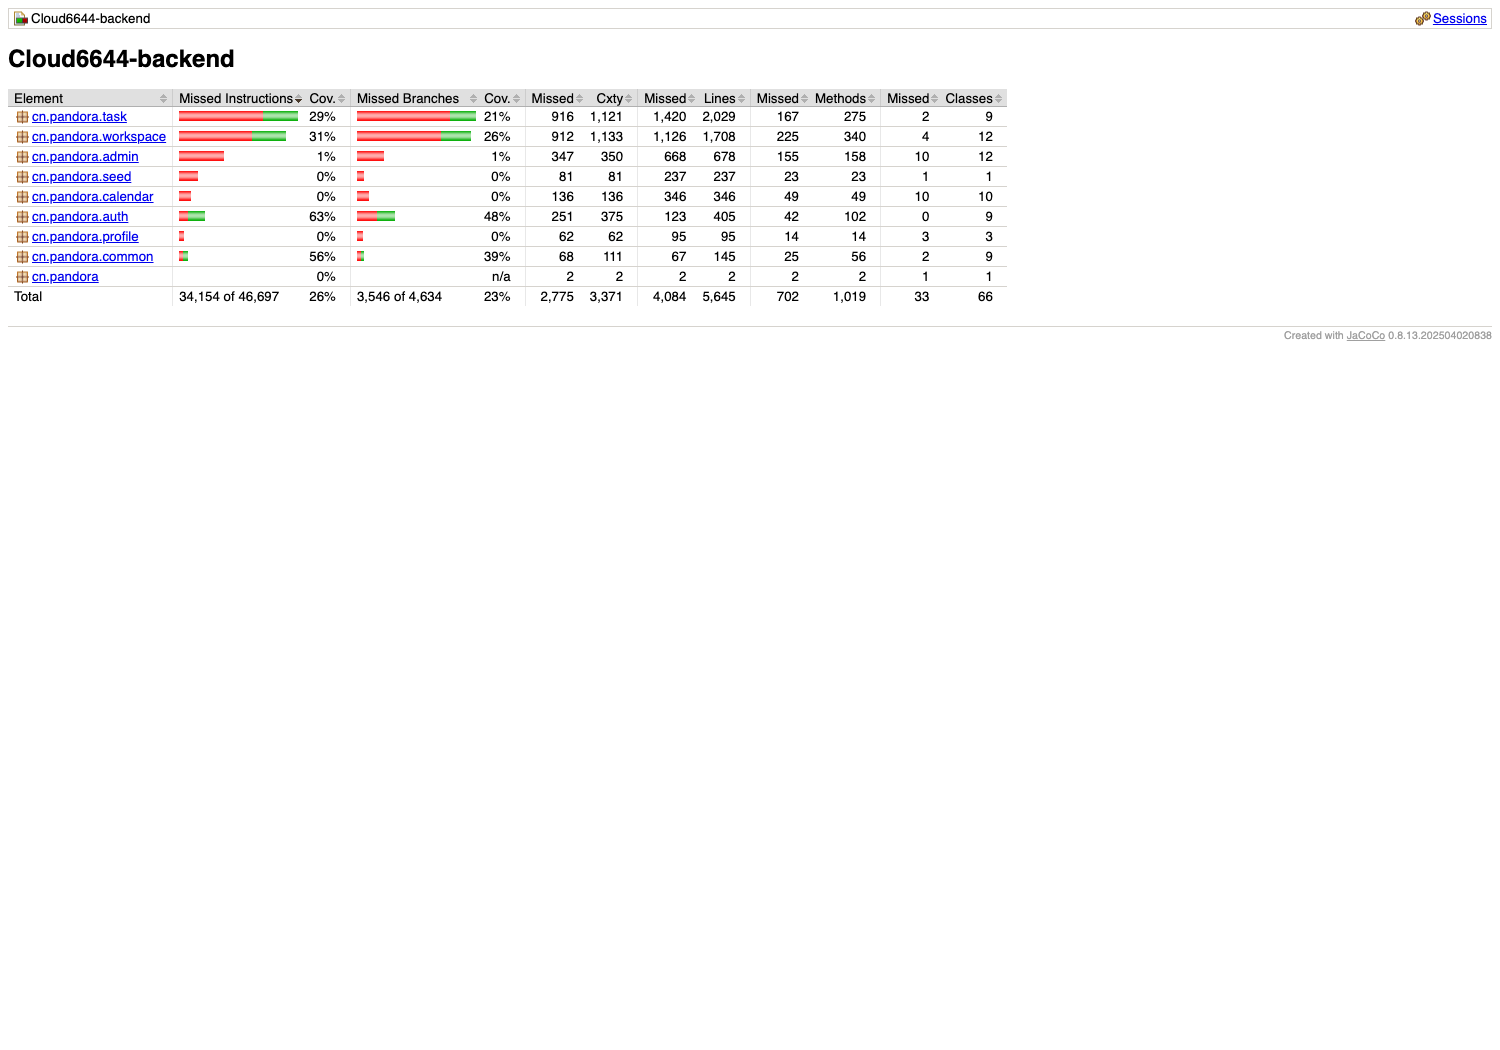

**覆盖率分析：** 实际行覆盖为1561/5645（27.65%），尚有4084行未执行；分支覆盖为1088/4634（23.48%），尚有3546个分支未执行。33/66个应用类、317/1019个方法有执行。因此126项专项断言通过只能支持所列场景，不能推断全部后端分支已覆盖；共享窗口还可能包含后台请求。原启动配置已恢复。

In [54]:
await show_coverage(COVERAGE)

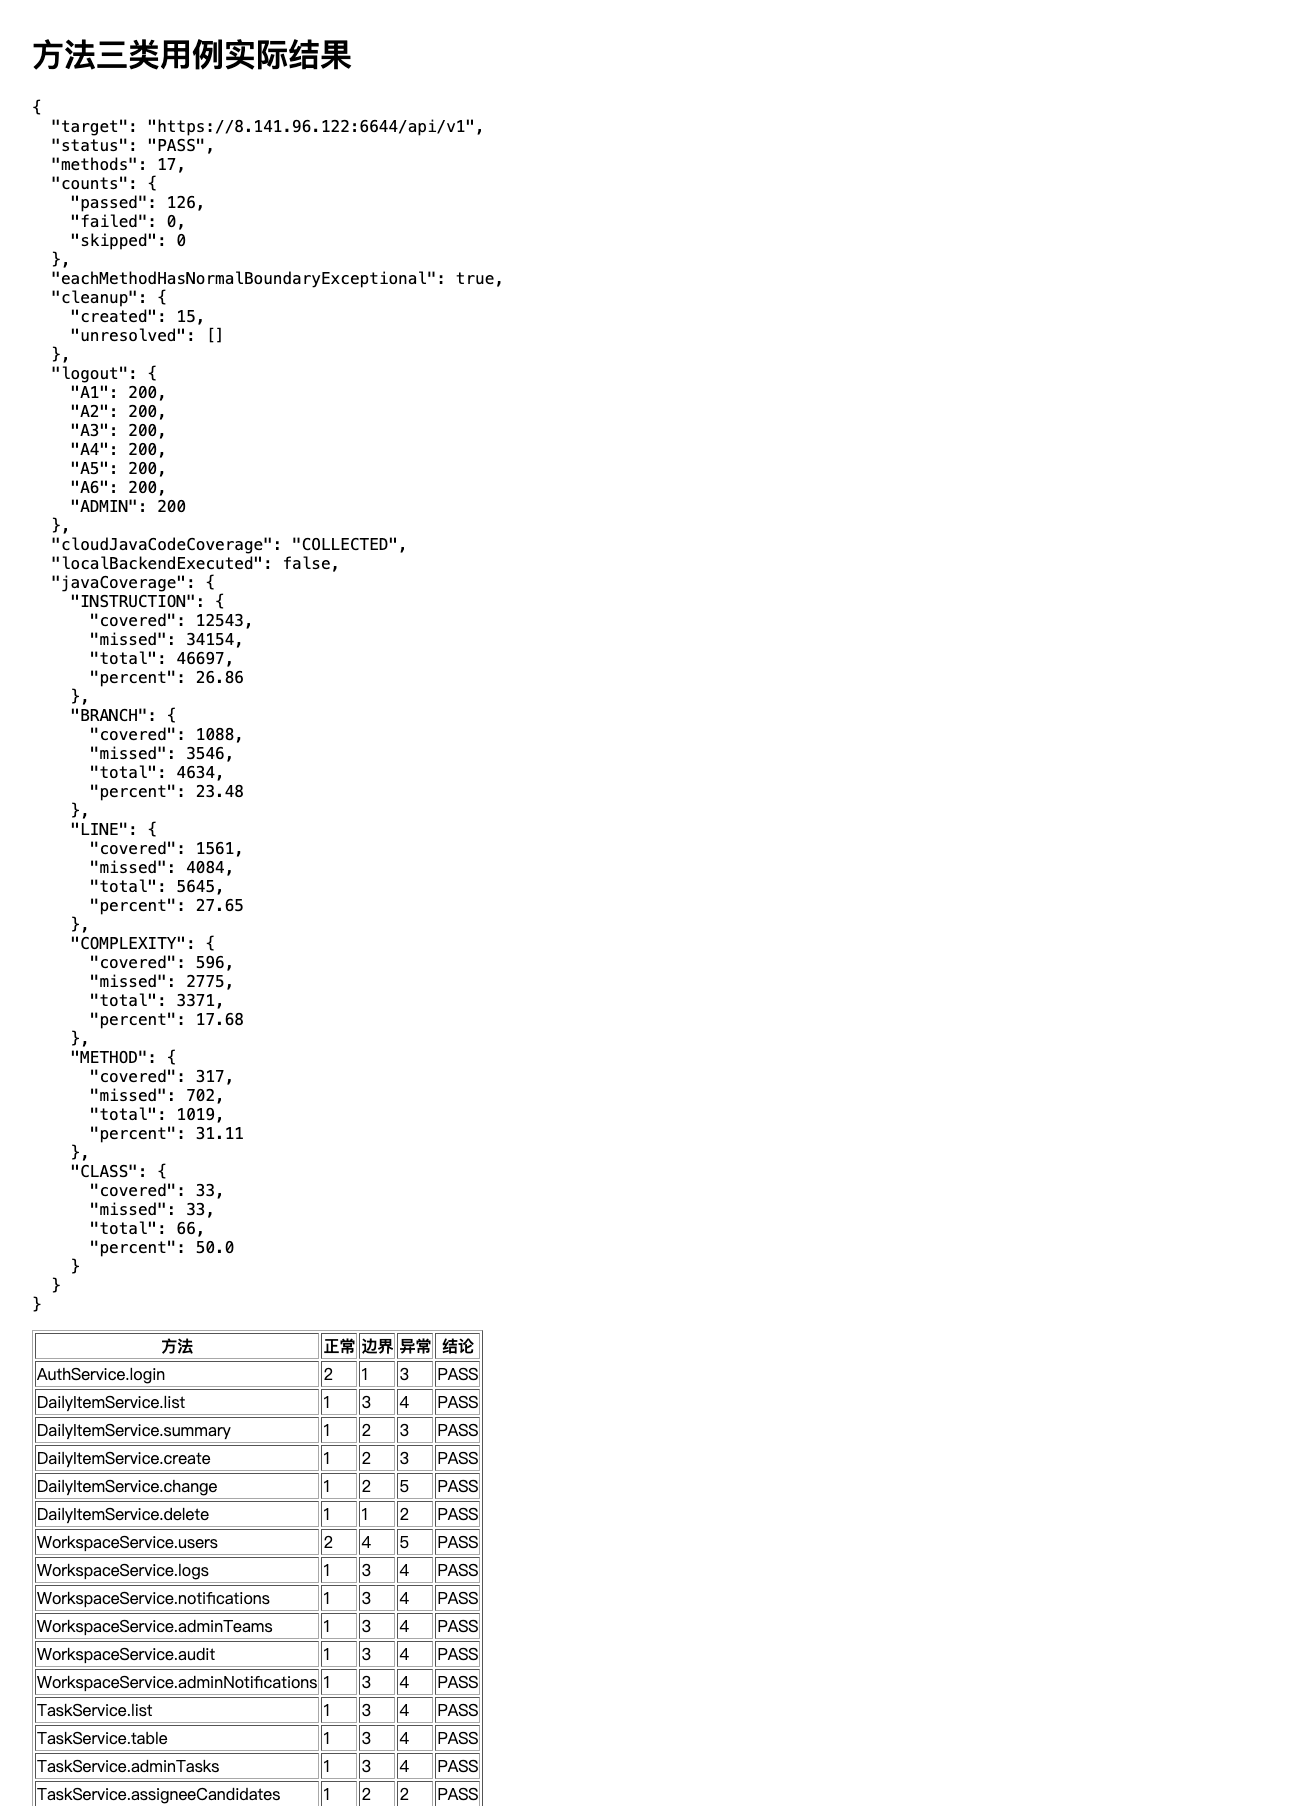

In [55]:
from playwright.async_api import async_playwright
async with async_playwright() as pw:
    edge=Path('/Applications/Microsoft Edge.app/Contents/MacOS/Microsoft Edge')
    browser=await pw.chromium.launch(executable_path=str(edge) if edge.exists() else None,headless=True)
    page=await browser.new_page(viewport={'width':1300,'height':1000})
    await page.goto((RUN/'测试结果.html').as_uri())
    await page.screenshot(path=str(RUN/'pytest三类用例结果.png'),full_page=True)
    await browser.close()
display(Image(filename=str(RUN/'pytest三类用例结果.png')))
assert summary['status']=='PASS','本次未完整达标，请核对逐方法三类覆盖和失败原始数据'

<a id="reproduce"></a>
## 04　复现说明

1. 打开 `测试报告.ipynb`，选择已安装依赖的 Python 内核。
2. 重启内核并运行全部单元格，在隐藏输入框提供应用凭据；需要重新采集覆盖率时再提供 SSH 凭据。
3. 查看每个方法的数据对照表和结论；详细请求、响应与 pytest 日志可点击展开。
4. 完成后核对总体结果、清理状态和覆盖率记录。

每次运行创建独立目录，保存原始数据和报告。安装依赖与证据文件说明见同目录 `README.md`。